# Project #2 - Polynomial Regression

## 1 Setup

### 1.1 Libraries

#### Import Libraries

In [1]:
# Data manipulation libraries.
import numpy as np
import pandas as pd

# Data visualization libraries.
import matplotlib.pyplot as plt
import seaborn as sns

# Data modeling libraries.
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor as VIF
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

#### Configure Libraries

In [2]:
RANDOM_STATE = 42

# Configure NumPy.
rng = np.random.default_rng(seed=RANDOM_STATE)
np.set_printoptions(linewidth=100)

# Configure Pandas.
pd.options.display.width = 100
pd.options.display.max_columns = None

# Configure Seaborn.
sns.set_style("whitegrid")
sns.set_palette("deep")

#### Helper Functions

In [3]:
# Import `ml_utils.ipynb` containing helper functions.
%run ./ml_utils.ipynb

### 1.2 Dataset

#### Import Dataset

In [4]:
add_df = pd.read_csv("data/advertising.csv")

display(add_df.sample(5, random_state=rng))

row_count, col_count = add_df.shape
print(f"Dataset contains {row_count:,} rows and {col_count} columns.")

,TV,Radio,Newspaper,Sales
152,197.6,23.3,14.2,16.6
87,110.7,40.6,63.2,16.0
129,59.6,12.0,43.1,9.7
17,281.4,39.6,55.8,24.4
86,76.3,27.5,16.0,12.0


Dataset contains 200 rows and 4 columns.


#### Metadata

In [5]:
add_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


## 2 EDA

### 2.1 Univariate Analysis

#### Correlation Matrix

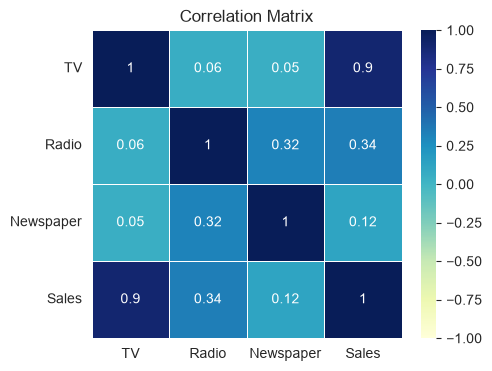

In [6]:
corr = add_df.corr(numeric_only=True, method="spearman").round(2)

plt.figure(figsize=(5, 4))
sns.heatmap(corr, cmap="YlGnBu", linecolor="white", linewidth=0.5, vmin=-1, vmax=1, annot=True)
plt.title("Correlation Matrix")
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.show()

#### Distributions

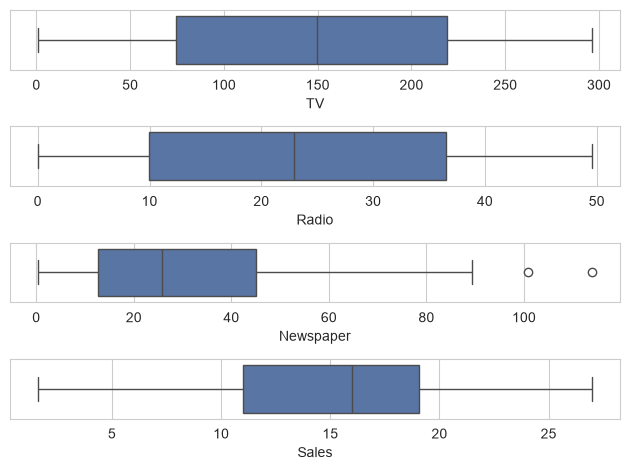

In [7]:
for idx, col_name in enumerate(add_df.columns):
    plt.subplot(col_count, 1, idx + 1)
    sns.boxplot(add_df, x=col_name)

plt.tight_layout()
plt.show()

#### Check for Multicollinearity

In [8]:
get_vif_ledger(df=add_df.drop(columns="Sales"))

,Feature,VIF
0,Newspaper,1.145187
1,Radio,1.144952
2,TV,1.004611
3,const,1.000000


### 2.2 Bi-variate Analysis

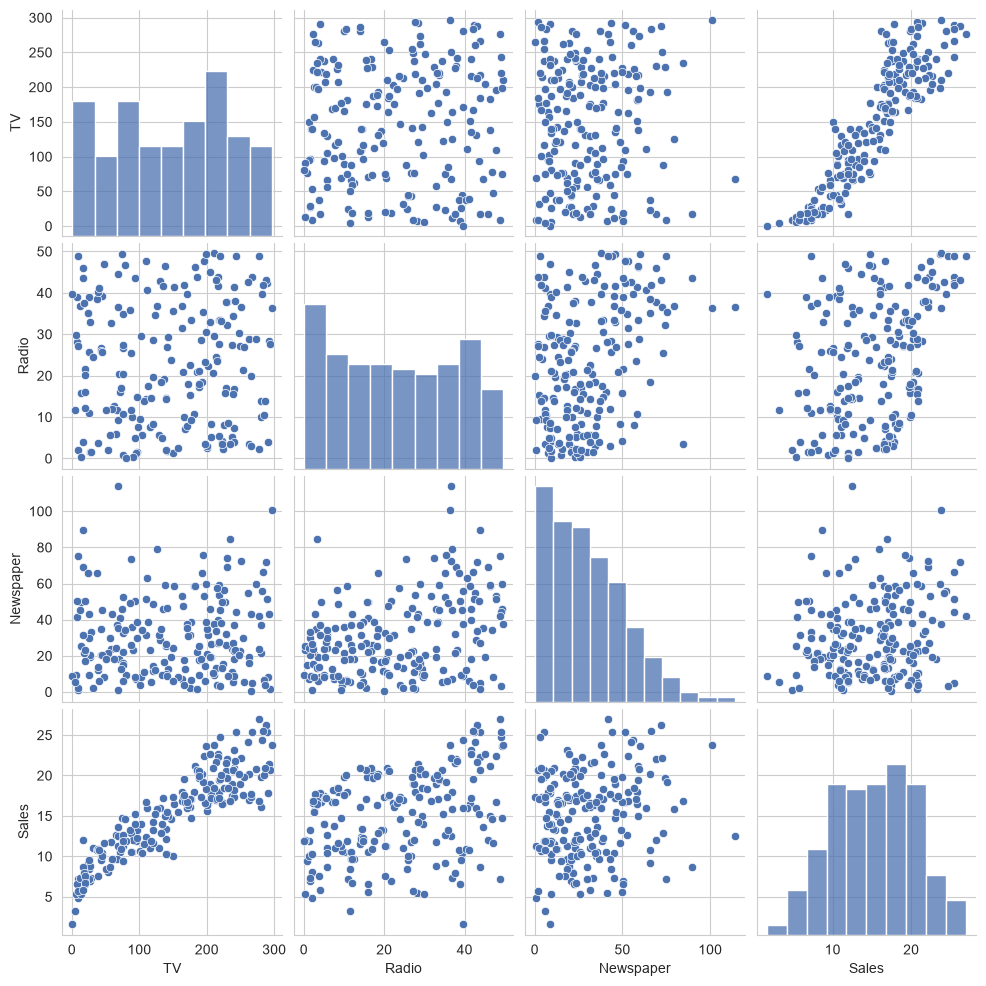

In [9]:
sns.pairplot(add_df)
plt.show()

## 3 Training Pipeline

### 3.1 Training Setup

#### Split Features and Target

In [10]:
target = "Sales"
X = add_df.drop(columns=target)
y = add_df[target]

X.shape, y.shape

((200, 3), (200,))

#### Train Test split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((140, 3), (60, 3), (140,), (60,))

#### Feature Scaling

In [12]:
sclr = StandardScaler().set_output(transform="pandas")
X_train_scld = sclr.fit_transform(X_train)
X_train_scld.head()

,TV,Radio,Newspaper
169,1.530039,-0.886293,-1.165980
97,0.341039,-0.173144,-0.409601
31,-0.520209,-0.420003,0.395263
12,-1.586003,0.793721,1.718926
35,1.606594,-1.332011,-1.064160


In [13]:
X_test_scld = sclr.transform(X_test)
X_test_scld.head()

,TV,Radio,Newspaper
95,0.082664,0.553719,1.088611
15,0.466637,1.657728,1.088611
30,1.632910,0.327431,0.618298
158,-1.730740,0.917150,0.715270
128,0.764485,1.746871,-1.321135


### 3.2 Base Model

#### Training

In [14]:
base_model = LinearRegression()
base_model.fit(X_train_scld, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[4.48,1.5 ,0.16]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['TV','Radio','Newspaper']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,15.78
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


#### Training R-squared

In [15]:
base_model.score(X_train_scld, y_train)

0.8919647339302077

#### Testing R-squared

In [16]:
base_model.score(X_test_scld, y_test)

0.9091484341849799

### 3.3 Polynomial Features

#### Add Train Polynomial Features

In [17]:
p_ftrs = PolynomialFeatures(degree=2, include_bias=False).set_output(transform="pandas")
X_train_poly = p_ftrs.fit_transform(X_train_scld)
X_train_poly.head()

,TV,Radio,Newspaper,TV^2,TV Radio,TV Newspaper,Radio^2,Radio Newspaper,Newspaper^2
169,1.530039,-0.886293,-1.165980,2.341019,-1.356062,-1.783995,0.785515,1.033400,1.359510
97,0.341039,-0.173144,-0.409601,0.116307,-0.059049,-0.139690,0.029979,0.070920,0.167773
31,-0.520209,-0.420003,0.395263,0.270617,0.218490,-0.205620,0.176403,-0.166012,0.156233
12,-1.586003,0.793721,1.718926,2.515405,-1.258843,-2.726222,0.629993,1.364347,2.954708
35,1.606594,-1.332011,-1.064160,2.581145,-2.140001,-1.709673,1.774253,1.417473,1.132436


#### Check for Multicollinearity

In [18]:
get_vif_ledger(X_train_poly)

,Feature,VIF
0,Newspaper^2,1.738712
1,Radio Newspaper,1.559780
2,Newspaper,1.451574
3,TV Newspaper,1.283595
4,Radio^2,1.190870
5,TV Radio,1.188711
6,Radio,1.174351
7,TV^2,1.105453
8,TV,1.085542
9,const,1.000000


#### Add Test Polynomial Features

In [19]:
X_test_poly = p_ftrs.transform(X_test_scld)
X_test_poly.head()

,TV,Radio,Newspaper,TV^2,TV Radio,TV Newspaper,Radio^2,Radio Newspaper,Newspaper^2
95,0.082664,0.553719,1.088611,0.006833,0.045773,0.089989,0.306604,0.602784,1.185073
15,0.466637,1.657728,1.088611,0.217750,0.773558,0.507986,2.748061,1.804620,1.185073
30,1.632910,0.327431,0.618298,2.666395,0.534666,1.009625,0.107211,0.202450,0.382293
158,-1.730740,0.917150,0.715270,2.995462,-1.587349,-1.237946,0.841165,0.656010,0.511611
128,0.764485,1.746871,-1.321135,0.584438,1.335458,-1.009988,3.051559,-2.307853,1.745397


### 3.4 Retrain Model

#### Training

In [20]:
model_2 = LinearRegression()
model_2.fit(X_train_poly, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](9,)","[4.32,1.49,0.09,...,0.39,0.05,0.07]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](9,)","['TV','Radio','Newspaper',...,'Radio^2','Radio Newspaper','Newspaper^2']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,16.06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)


#### Training R-squared

In [21]:
model_2.score(X_train_poly, y_train)

0.9238235326828356

#### Testing R-squared

In [22]:
model_2.score(X_test_poly, y_test)

0.9462913219526544